# Employee Attrition Analysis & Prediction
### Industrial Portfolio Project | HR Analytics | Python • SQL • Machine Learning • Power BI

**Purpose:** Analyze historical employee attrition, identify associated workforce patterns, train classification models, evaluate them responsibly, and export clean files for Power BI.

**Dataset:** IBM HR Analytics Employee Attrition sample dataset (fictional/sample records; not real company data).

**How to use this notebook**
1. Open this file in Google Colab.
2. Run cells from top to bottom using **Runtime → Run all** or Shift+Enter.
3. When prompted, upload `WA_Fn-UseC_-HR-Employee-Attrition.csv`.
4. At the end, download the ZIP containing all Power BI-ready CSV outputs.

**Important:** Model predictions are statistical estimates from historical sample data. They are not proof of why an individual leaves and must not be used for automated employment decisions.

## 1. Environment setup

Import the libraries used for data analysis, SQL, visualization, and machine learning.

In [1]:
import os
import zipfile
import sqlite3
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix
)
from sklearn.inspection import permutation_importance
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

RANDOM_STATE = 42
print("Environment ready.")

Environment ready.


## 2. Upload and load the HR dataset

Upload the original CSV file, not the ZIP archive. The standard IBM sample file is commonly named `WA_Fn-UseC_-HR-Employee-Attrition.csv`.

In [2]:
uploaded = files.upload()
csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("No CSV file uploaded. Please upload the HR attrition CSV.")

csv_name = csv_files[0]
raw_df = pd.read_csv(csv_name)

print(f"Loaded: {csv_name}")
print(f"Rows: {raw_df.shape[0]:,}")
print(f"Columns: {raw_df.shape[1]}")
display(raw_df.head())

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Loaded: WA_Fn-UseC_-HR-Employee-Attrition.csv
Rows: 1,470
Columns: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


## 3. Initial data inspection and quality checks

Check dimensions, column names, data types, missing values, duplicates, and the target distribution.

In [3]:
print("Dataset information:")
raw_df.info()

print("\nMissing values (largest first):")
display(raw_df.isna().sum().sort_values(ascending=False).head(20).to_frame("Missing values"))

print("Duplicate rows:", raw_df.duplicated().sum())

if "Attrition" not in raw_df.columns:
    raise ValueError("The dataset must contain an 'Attrition' column.")

print("\nAttrition counts:")
display(raw_df["Attrition"].value_counts(dropna=False).to_frame("Employee records"))

print("\nAttrition percentage:")
display((raw_df["Attrition"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("Percentage"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  Job

,Missing values
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


Duplicate rows: 0

Attrition counts:


,Employee records
Attrition,
No,1233
Yes,237



Attrition percentage:


,Percentage
Attrition,
No,83.88
Yes,16.12


## 4. Prepare the analysis dataset and create HR groupings

Keep `raw_df` unchanged as the source. Create `df` for analysis and Power BI. The group columns are for dashboard slicing; the original numerical variables remain available.

In [4]:
df = raw_df.copy()

# Normalize target labels
df["Attrition"] = df["Attrition"].astype("string").str.strip().str.title()

# Remove exact duplicate records, if any
before = len(df)
df = df.drop_duplicates().copy()
print(f"Duplicate rows removed: {before - len(df)}")

# Validate target values
target_values = set(df["Attrition"].dropna().unique())
if not target_values.issubset({"Yes", "No"}) or not target_values:
    raise ValueError(f"Unexpected Attrition values: {target_values}")

# Create age bands for dashboard analysis
if "Age" in df.columns:
    df["AgeGroup"] = pd.cut(
        df["Age"], bins=[0, 25, 35, 45, 55, np.inf],
        labels=["Under 25", "25-34", "35-44", "45-54", "55+"],
        right=False
    ).astype("string")

# Create salary quartile bands; convert intervals to text for SQL/CSV compatibility
if "MonthlyIncome" in df.columns:
    salary_bins = pd.qcut(df["MonthlyIncome"], q=4, duplicates="drop")
    df["SalaryBand"] = salary_bins.astype("string")

# Create tenure bands
if "YearsAtCompany" in df.columns:
    df["TenureGroup"] = pd.cut(
        df["YearsAtCompany"],
        bins=[-1, 1, 3, 5, 10, np.inf],
        labels=["0-1 years", "2-3 years", "4-5 years", "6-10 years", "10+ years"]
    ).astype("string")

print("Analysis dataset shape:", df.shape)
display(df.head())

Duplicate rows removed: 0
Analysis dataset shape: (1470, 38)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,SalaryBand,TenureGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,35-44,"(4919.0, 8379.0]",6-10 years
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,45-54,"(4919.0, 8379.0]",6-10 years
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,35-44,"(1008.999, 2911.0]",0-1 years
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,25-34,"(1008.999, 2911.0]",6-10 years
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,25-34,"(2911.0, 4919.0]",2-3 years


## 5. Exploratory Data Analysis (EDA)

### 5.1 Overall HR KPIs

Attrition rate = employees marked `Yes` divided by all employee records. The sample does not establish a defined annual observation window, so do not label this an annual attrition rate.

In [5]:
total_employees = len(df)
employees_left = int(df["Attrition"].eq("Yes").sum())
active_employees = int(df["Attrition"].eq("No").sum())
attrition_rate = employees_left / total_employees if total_employees else 0

kpi_summary = pd.DataFrame({
    "KPI": ["Total Employees", "Employees Left", "Active Employees", "Attrition Rate"],
    "Value": [total_employees, employees_left, active_employees, attrition_rate]
})
display(kpi_summary)
print(f"Attrition rate: {attrition_rate:.2%}")

,KPI,Value
0,Total Employees,1470.000000
1,Employees Left,237.000000
2,Active Employees,1233.000000
3,Attrition Rate,0.161224


Attrition rate: 16.12%


### 5.2 Attrition distribution

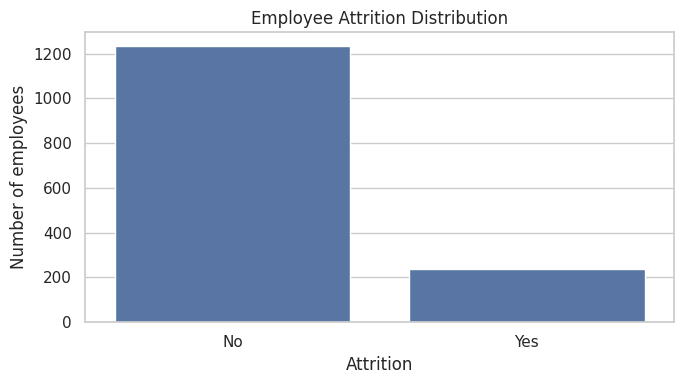

In [6]:
attrition_counts = df["Attrition"].value_counts().reindex(["No", "Yes"], fill_value=0)
plt.figure(figsize=(7, 4))
sns.barplot(x=attrition_counts.index, y=attrition_counts.values)
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of employees")
plt.tight_layout()
plt.show()

### 5.3 Attrition by department, age group, salary band, overtime, satisfaction, and tenure

The following helper calculates the **rate within each group**, rather than comparing departure counts alone.

In [7]:
def attrition_rate_by(column):
    result = (
        df.groupby(column, dropna=False)["Attrition"]
          .agg(total_employees="size",
               employees_left=lambda s: s.eq("Yes").sum())
          .reset_index()
    )
    result["attrition_rate_pct"] = (
        result["employees_left"] / result["total_employees"] * 100
    ).round(2)
    return result.sort_values("attrition_rate_pct", ascending=False)

eda_columns = [
    col for col in
    ["Department", "AgeGroup", "SalaryBand", "OverTime",
     "JobSatisfaction", "TenureGroup", "JobRole"]
    if col in df.columns
]

eda_tables = {}
for col in eda_columns:
    print(f"Attrition by {col}")
    eda_tables[col] = attrition_rate_by(col)
    display(eda_tables[col])

Attrition by Department


,Department,total_employees,employees_left,attrition_rate_pct
2,Sales,446,92,20.63
0,Human Resources,63,12,19.05
1,Research & Development,961,133,13.84


Attrition by AgeGroup


,AgeGroup,total_employees,employees_left,attrition_rate_pct
4,Under 25,97,38,39.18
0,25-34,554,112,20.22
3,55+,69,11,15.94
2,45-54,245,25,10.20
1,35-44,505,51,10.10


Attrition by SalaryBand


,SalaryBand,total_employees,employees_left,attrition_rate_pct
0,"(1008.999, 2911.0]",369,108,29.27
1,"(2911.0, 4919.0]",366,52,14.21
2,"(4919.0, 8379.0]",367,39,10.63
3,"(8379.0, 19999.0]",368,38,10.33


... (4 outputs left out)

Attrition by TenureGroup


,TenureGroup,total_employees,employees_left,attrition_rate_pct
0,0-1 years,215,75,34.88
2,2-3 years,255,47,18.43
3,4-5 years,306,40,13.07
4,6-10 years,448,55,12.28
1,10+ years,246,20,8.13


Attrition by JobRole


,JobRole,total_employees,employees_left,attrition_rate_pct
8,Sales Representative,83,33,39.76
2,Laboratory Technician,259,62,23.94
1,Human Resources,52,12,23.08
7,Sales Executive,326,57,17.48
6,Research Scientist,292,47,16.10
4,Manufacturing Director,145,10,6.90
0,Healthcare Representative,131,9,6.87
3,Manager,102,5,4.90
5,Research Director,80,2,2.50


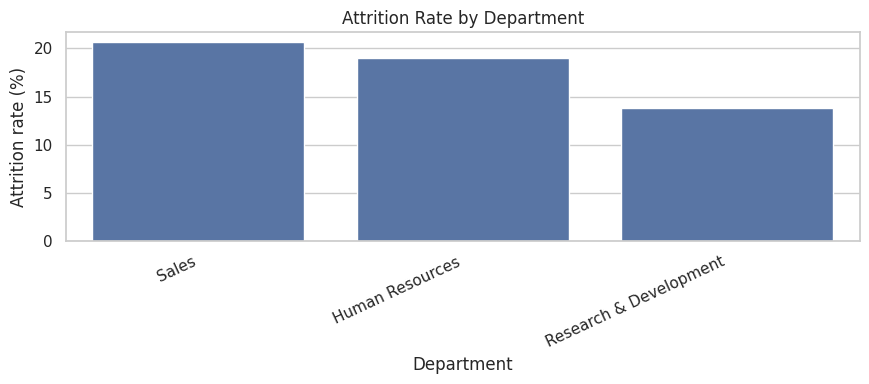

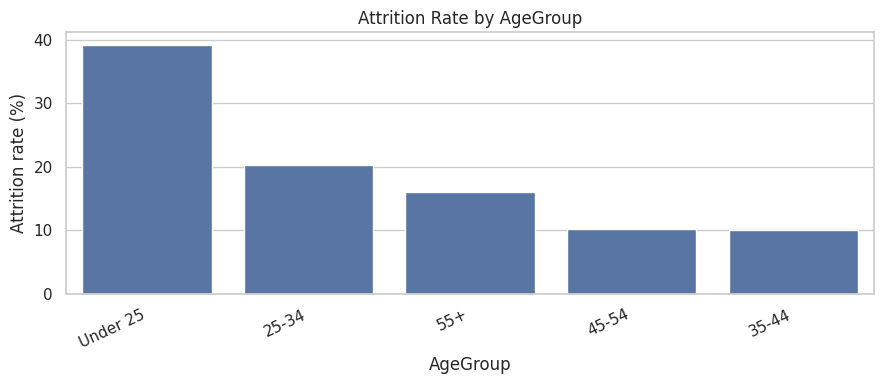

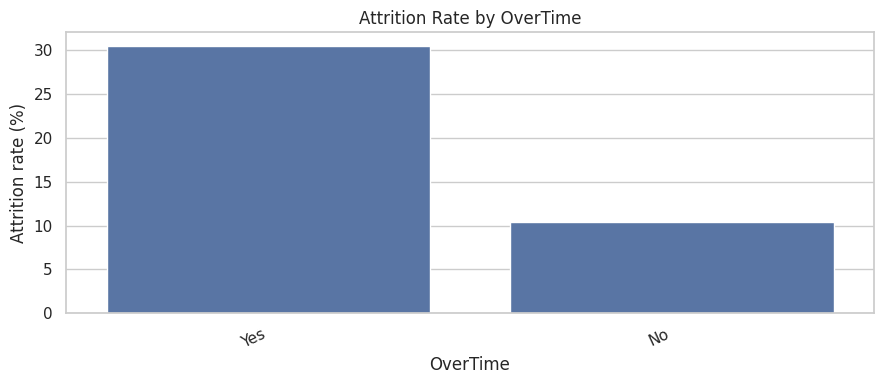

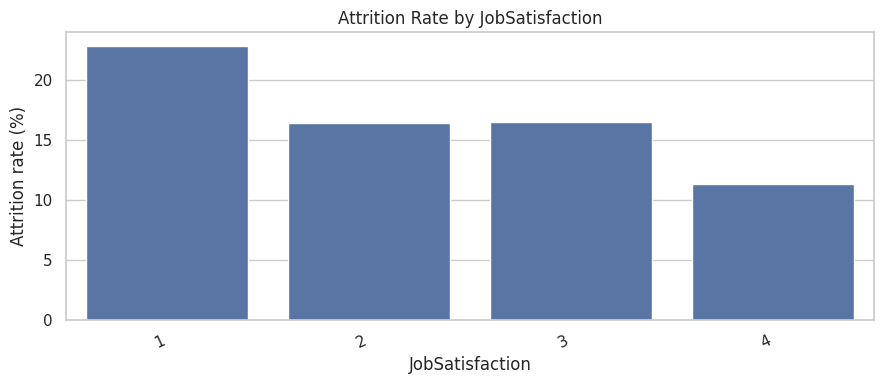

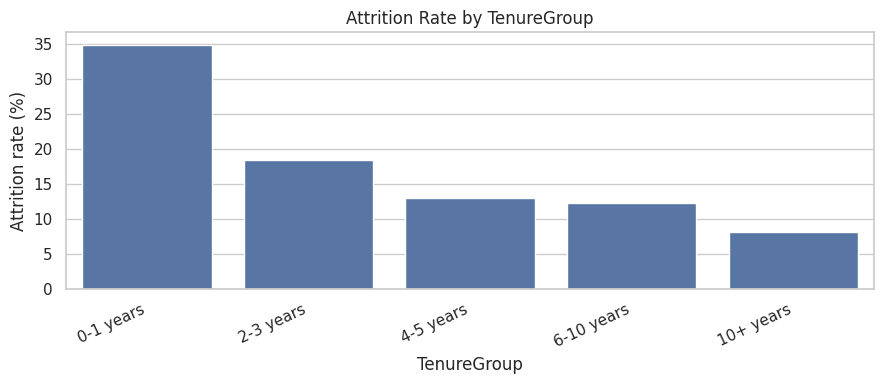

In [8]:
# Plot the key group-level attrition rates
plot_columns = [c for c in ["Department", "AgeGroup", "OverTime", "JobSatisfaction", "TenureGroup"] if c in df.columns]

for col in plot_columns:
    plot_df = attrition_rate_by(col).copy()
    plt.figure(figsize=(9, 4))
    sns.barplot(data=plot_df, x=col, y="attrition_rate_pct")
    plt.title(f"Attrition Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Attrition rate (%)")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### 5.4 Compare employee averages by attrition status

In [9]:
numeric_candidates = [
    "Age", "MonthlyIncome", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion",
    "TotalWorkingYears"
]
numeric_columns = [c for c in numeric_candidates if c in df.columns]

group_summary = df.groupby("Attrition")[numeric_columns].mean().T.round(2)
display(group_summary)

Attrition,No,Yes
Age,37.56,33.61
MonthlyIncome,6832.74,4787.09
YearsAtCompany,7.37,5.13
YearsInCurrentRole,4.48,2.90
YearsSinceLastPromotion,2.23,1.95
TotalWorkingYears,11.86,8.24


### 5.5 Correlation heatmap for numerical variables

This shows correlations among numeric variables; it does not establish causation.

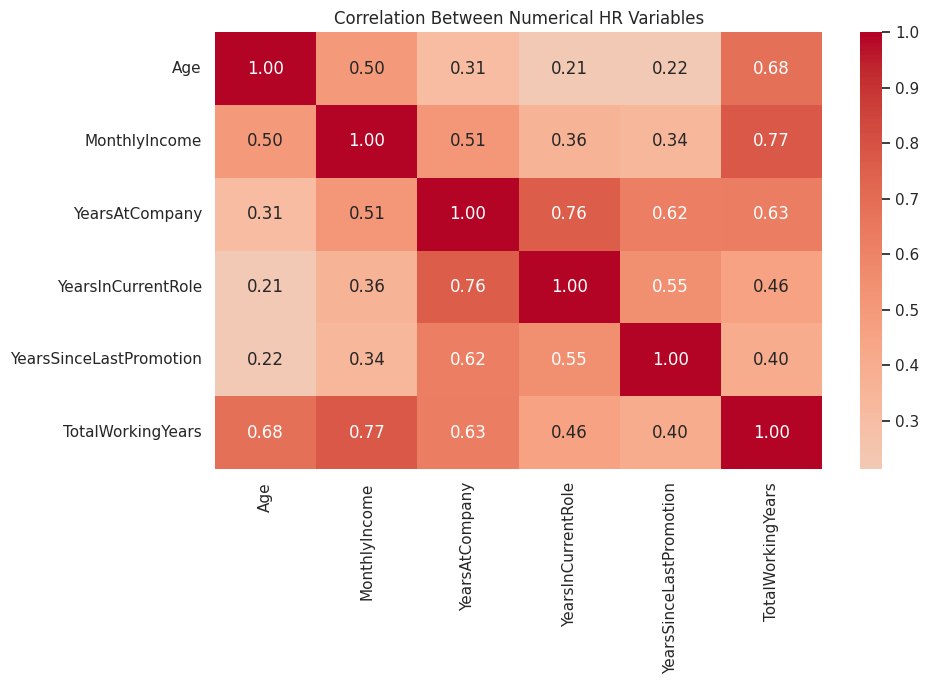

In [10]:
corr_columns = [c for c in numeric_columns if pd.api.types.is_numeric_dtype(df[c])]
if len(corr_columns) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(df[corr_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation Between Numerical HR Variables")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

## 6. SQL analysis using SQLite

Create a local SQLite database from the analysis dataset. Category/group columns are converted to strings to avoid the pandas Interval-to-SQLite error.

In [11]:
# Convert pandas extension/category types into SQLite-compatible values
sql_df = df.copy()
for col in sql_df.columns:
    if isinstance(sql_df[col].dtype, pd.CategoricalDtype):
        sql_df[col] = sql_df[col].astype("string")
    if pd.api.types.is_string_dtype(sql_df[col].dtype):
        sql_df[col] = sql_df[col].astype(object).where(sql_df[col].notna(), None)

conn = sqlite3.connect("employee_attrition.db")
sql_df.to_sql("hr_employee_attrition", conn, if_exists="replace", index=False)

def run_sql(query):
    result = pd.read_sql_query(query, conn)
    display(result)
    return result

print("SQLite table created.")
run_sql("SELECT COUNT(*) AS total_records FROM hr_employee_attrition;")

SQLite table created.


,total_records
0,1470


,total_records
0,1470


### 6.1 SQL business queries

Run these queries to answer common HR questions. Each query returns a table that can also be exported for Power BI.

In [12]:
sql_queries = {
    "overall_kpis": '''
        SELECT COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               SUM(CASE WHEN Attrition = 'No' THEN 1 ELSE 0 END) AS employees_stayed,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
    ''',
    "department_attrition": '''
        SELECT Department, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY Department ORDER BY attrition_rate_pct DESC
    ''',
    "age_attrition": '''
        SELECT AgeGroup, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY AgeGroup ORDER BY AgeGroup
    ''',
    "salary_attrition": '''
        SELECT SalaryBand, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY SalaryBand ORDER BY MIN(MonthlyIncome)
    ''',
    "overtime_attrition": '''
        SELECT OverTime, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY OverTime
    ''',
    "satisfaction_attrition": '''
        SELECT JobSatisfaction, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY JobSatisfaction ORDER BY JobSatisfaction
    ''',
    "tenure_attrition": '''
        SELECT TenureGroup, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY TenureGroup ORDER BY MIN(YearsAtCompany)
    ''',
    "jobrole_attrition": '''
        SELECT JobRole, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY JobRole ORDER BY attrition_rate_pct DESC
    ''',
    "department_jobrole": '''
        SELECT Department, JobRole, COUNT(*) AS total_employees,
               SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
               ROUND(100.0 * SUM(CASE WHEN Attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS attrition_rate_pct
        FROM hr_employee_attrition
        GROUP BY Department, JobRole
        HAVING COUNT(*) >= 10
        ORDER BY attrition_rate_pct DESC
    ''',
    "attrition_group_comparison": '''
        SELECT Attrition, COUNT(*) AS employee_count,
               ROUND(AVG(Age), 2) AS average_age,
               ROUND(AVG(MonthlyIncome), 2) AS average_monthly_income,
               ROUND(AVG(YearsAtCompany), 2) AS average_tenure
        FROM hr_employee_attrition
        GROUP BY Attrition
    '''
}

sql_results = {}
for output_name, query in sql_queries.items():
    print("\n", output_name)
    sql_results[output_name] = run_sql(query)


 overall_kpis


,total_employees,employees_left,employees_stayed,attrition_rate_pct
0,1470,237,1233,16.12



 department_attrition


,Department,total_employees,employees_left,attrition_rate_pct
0,Sales,446,92,20.63
1,Human Resources,63,12,19.05
2,Research & Development,961,133,13.84



 age_attrition


,AgeGroup,total_employees,employees_left,attrition_rate_pct
0,25-34,554,112,20.22
1,35-44,505,51,10.10
2,45-54,245,25,10.20
3,55+,69,11,15.94
4,Under 25,97,38,39.18


... (10 outputs left out)


 department_jobrole


,Department,JobRole,total_employees,employees_left,attrition_rate_pct
0,Sales,Sales Representative,83,33,39.76
1,Research & Development,Laboratory Technician,259,62,23.94
2,Human Resources,Human Resources,52,12,23.08
3,Sales,Sales Executive,326,57,17.48
4,Research & Development,Research Scientist,292,47,16.10
5,Research & Development,Manufacturing Director,145,10,6.90
6,Research & Development,Healthcare Representative,131,9,6.87
7,Research & Development,Manager,54,3,5.56
8,Sales,Manager,37,2,5.41
9,Research & Development,Research Director,80,2,2.50



 attrition_group_comparison


,Attrition,employee_count,average_age,average_monthly_income,average_tenure
0,No,1233,37.56,6832.74,7.37
1,Yes,237,33.61,4787.09,5.13


## 7. Machine learning: prepare features and target

We predict `Attrition` (`Yes` = 1, `No` = 0). Derived grouping columns are excluded from model features to avoid duplicating the original age, salary, and tenure information. Employee identifiers and constant columns are also excluded.

In [13]:
model_df = df.copy()

# Keep only valid target rows
model_df = model_df[model_df["Attrition"].isin(["Yes", "No"])].copy()

# Remove duplicate rows and non-predictive identifiers / EDA-only groups
drop_candidates = ["EmployeeNumber", "AgeGroup", "SalaryBand", "TenureGroup"]
model_df = model_df.drop(columns=drop_candidates, errors="ignore")

# Remove constant columns
constant_columns = [
    c for c in model_df.columns
    if c != "Attrition" and model_df[c].nunique(dropna=False) <= 1
]
model_df = model_df.drop(columns=constant_columns)

X = model_df.drop(columns=["Attrition"])
y = model_df["Attrition"].map({"No": 0, "Yes": 1}).astype(int)

print("Features:", X.shape)
print("Target distribution:")
display(y.value_counts().rename(index={0: "Stayed (0)", 1: "Left (1)"}).to_frame("Count"))
print("Removed constant columns:", constant_columns)

Features: (1470, 30)
Target distribution:


,Count
Attrition,
Stayed (0),1233
Left (1),237


Removed constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


## 8. Train/test split and preprocessing

Use a stratified 80/20 split so the proportion of attrition cases is similar in training and test data. Imputation, scaling, and encoding are fitted inside the pipeline using training data only.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training records: 1176
Testing records: 294
Numeric features: 23
Categorical features: 7


## 9. Train three classification models

The dataset is imbalanced: more employees stayed than left. Class weighting gives additional importance to the minority `Left` class without creating synthetic employee records. These are baseline configurations; tuning should be done using cross-validation on training data only.

In [15]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "Decision Tree": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5, min_samples_split=10, min_samples_leaf=5,
            class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300, max_depth=10, min_samples_split=10,
            min_samples_leaf=3, class_weight="balanced_subsample",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained.")

Logistic Regression trained.
Decision Tree trained.
Random Forest trained.


## 10. Evaluate models

Compare accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC. For attrition, pay particular attention to recall and precision for the `Left` class; accuracy alone can be misleading with imbalanced data.

In [16]:
predictions = {}
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = {"predicted": y_pred, "probability": y_prob}

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    })

model_comparison = pd.DataFrame(results).sort_values(
    ["F1 Score", "Recall"], ascending=False
).reset_index(drop=True)

display(model_comparison.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "F1 Score": "{:.3f}", "ROC AUC": "{:.3f}", "PR AUC": "{:.3f}"
}))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.752,0.349,0.638,0.451,0.803,0.561
1,Decision Tree,0.759,0.329,0.489,0.393,0.632,0.322
2,Random Forest,0.833,0.469,0.319,0.380,0.787,0.437


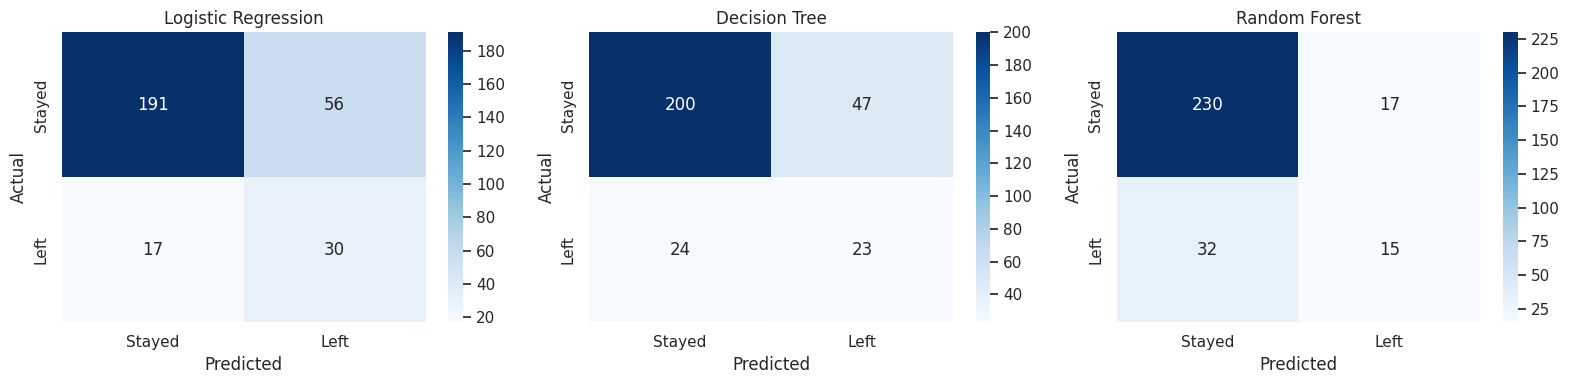


Logistic Regression
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294


Decision Tree
              precision    recall  f1-score   support

      Stayed       0.89      0.81      0.85       247
        Left       0.33      0.49      0.39        47

    accuracy                           0.76       294
   macro avg       0.61      0.65      0.62       294
weighted avg       0.80      0.76      0.78       294


Random Forest
              precision    recall  f1-score   support

      Stayed       0.88      0.93      0.90       247
        Left       0.47      0.32      0.38        47

    accuracy                           0.83       294
   macro avg       0.67      0.63      0.64       294
weighted avg       0.81

In [17]:
# Confusion matrices and detailed reports
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions[name]["predicted"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Stayed", "Left"],
                yticklabels=["Stayed", "Left"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

for name in models:
    print("\n" + "=" * 50)
    print(name)
    print(classification_report(
        y_test, predictions[name]["predicted"],
        labels=[0, 1], target_names=["Stayed", "Left"], zero_division=0
    ))

## 11. Feature importance using permutation importance

Permutation importance measures how much a chosen evaluation score falls when a feature is shuffled. A higher value means the model relies more on that feature for this test set and metric. It is not causal evidence.

In [18]:
# Use the model with the best F1 score as an initial candidate
best_model_name = model_comparison.iloc[0]["Model"]
best_model = models[best_model_name]
print("Initial model candidate:", best_model_name)

importance_result = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="average_precision", n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(feature_importance.head(15))

Initial model candidate: Logistic Regression


,Feature,Importance,Std
0,OverTime,0.232896,0.022963
1,TotalWorkingYears,0.071079,0.029240
2,JobSatisfaction,0.064414,0.014835
3,NumCompaniesWorked,0.062441,0.012472
4,JobRole,0.050738,0.027771
5,YearsSinceLastPromotion,0.047265,0.027818
6,EnvironmentSatisfaction,0.043116,0.021790
7,MonthlyIncome,0.029816,0.011340
8,YearsWithCurrManager,0.028271,0.019973
9,JobInvolvement,0.022880,0.008864


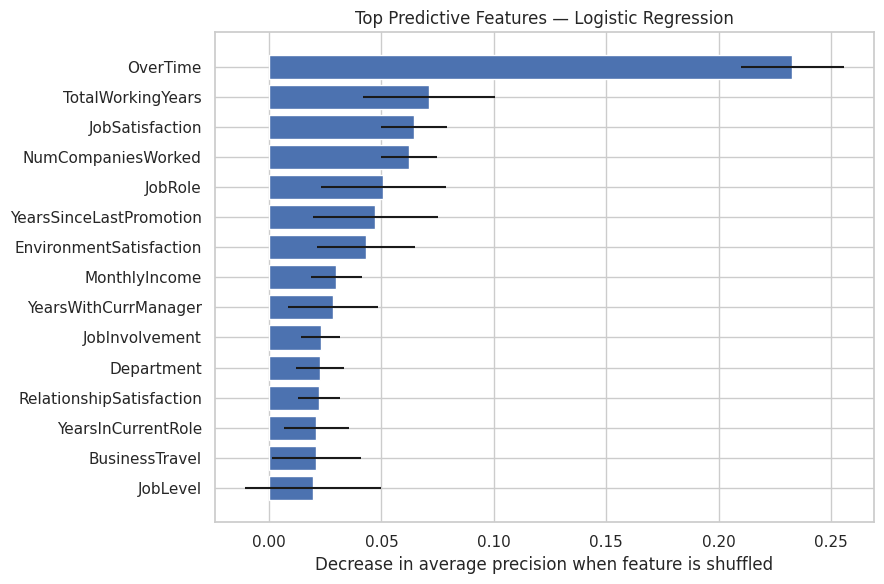

In [19]:
top_features = feature_importance.head(15).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"],
         xerr=top_features["Std"])
plt.title(f"Top Predictive Features — {best_model_name}")
plt.xlabel("Decrease in average precision when feature is shuffled")
plt.tight_layout()
plt.show()

## 12. Prepare employee-level test predictions

Preserve the original row index when splitting so predictions can be linked to the correct `EmployeeNumber`. These are predictions for the held-out test set only, not for every employee.

In [20]:
if "EmployeeNumber" not in df.columns:
    raise ValueError("EmployeeNumber is missing; cannot create employee-linked prediction output.")

# X retains the original dataframe index through the split
prediction_output = pd.DataFrame({
    "EmployeeNumber": df.loc[X_test.index, "EmployeeNumber"].values,
    "Actual_Attrition": y_test.values,
    "Predicted_Attrition": predictions[best_model_name]["predicted"],
    "Attrition_Probability": predictions[best_model_name]["probability"]
})

print("Prediction rows:", len(prediction_output))
print("Unique employee IDs:", prediction_output["EmployeeNumber"].nunique())
display(prediction_output.head())

Prediction rows: 294
Unique employee IDs: 294


,EmployeeNumber,Actual_Attrition,Predicted_Attrition,Attrition_Probability
0,1495,0,0,0.286610
1,1246,0,0,0.021878
2,613,0,0,0.407563
3,1288,0,0,0.040382
4,90,1,1,0.674098


## 13. Export all Power BI-ready files

This section creates:
- `employee_attrition_cleaned.csv` — employee-level source data, including dashboard groupings.
- SQL query outputs — summary tables.
- `model_comparison.csv` — model metrics.
- `feature_importance.csv` — permutation importance.
- `attrition_predictions_with_id.csv` — held-out test predictions linked by EmployeeNumber.
- `employee_attrition_model.pkl` — fitted preprocessing + model pipeline.
- `employee_attrition.db` — SQLite database.

All outputs are bundled into one ZIP file for download.

In [21]:
# Export main employee table
df.to_csv("employee_attrition_cleaned.csv", index=False)

# Export SQL result tables
for output_name, result in sql_results.items():
    result.to_csv(f"{output_name}.csv", index=False)

# Export machine-learning tables
model_comparison.to_csv("model_comparison.csv", index=False)
feature_importance.to_csv("feature_importance.csv", index=False)
prediction_output.to_csv("attrition_predictions_with_id.csv", index=False)

# Save the initial candidate model (pipeline includes preprocessing)
joblib.dump(best_model, "employee_attrition_model.pkl")

# Close database connection after writing
conn.commit()
conn.close()

# Bundle outputs
output_files = [
    "employee_attrition_cleaned.csv",
    "overall_kpis.csv",
    "department_attrition.csv",
    "age_attrition.csv",
    "salary_attrition.csv",
    "overtime_attrition.csv",
    "satisfaction_attrition.csv",
    "tenure_attrition.csv",
    "jobrole_attrition.csv",
    "department_jobrole.csv",
    "attrition_group_comparison.csv",
    "model_comparison.csv",
    "feature_importance.csv",
    "attrition_predictions_with_id.csv",
    "employee_attrition_model.pkl",
    "employee_attrition.db"
]

with zipfile.ZipFile("employee_attrition_project_outputs.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for filename in output_files:
        if os.path.exists(filename):
            zf.write(filename)

print("Export complete. Files included:")
for filename in output_files:
    if os.path.exists(filename):
        print("✓", filename)

files.download("employee_attrition_project_outputs.zip")

Export complete. Files included:
✓ employee_attrition_cleaned.csv
✓ overall_kpis.csv
✓ department_attrition.csv
✓ age_attrition.csv
✓ salary_attrition.csv
✓ overtime_attrition.csv
✓ satisfaction_attrition.csv
✓ tenure_attrition.csv
✓ jobrole_attrition.csv
✓ department_jobrole.csv
✓ attrition_group_comparison.csv
✓ model_comparison.csv
✓ feature_importance.csv
✓ attrition_predictions_with_id.csv
✓ employee_attrition_model.pkl
✓ employee_attrition.db


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Power BI handoff guide

After downloading and extracting `employee_attrition_project_outputs.zip`, import these files into Power BI:

| File | Suggested Power BI table |
|---|---|
| `employee_attrition_cleaned.csv` | `HR_Employees` |
| `model_comparison.csv` | `Model_Comparison` |
| `feature_importance.csv` | `Feature_Importance` |
| `attrition_predictions_with_id.csv` | `Model_Predictions` |

**Relationship:** `HR_Employees[EmployeeNumber]` (one) → `Model_Predictions[EmployeeNumber]` (many), single-direction filtering.

The SQL summary CSVs are optional: the same summaries can be calculated dynamically from `HR_Employees` using DAX.

### Suggested dashboard pages
1. **Executive Overview:** Total employees, employees left, active employees, attrition rate, department attrition, employee demographics.
2. **Attrition Drivers:** Attrition by age group, salary band, overtime, job satisfaction, tenure, and job role.
3. **Predictive Analytics:** Model comparison, precision/recall/F1/ROC-AUC, confusion matrix, feature importance, and test-set probability distribution.

### Core DAX measures

```dax
Total Employees =
DISTINCTCOUNT(HR_Employees[EmployeeNumber])

Employees Left =
CALCULATE([Total Employees], HR_Employees[Attrition] = "Yes")

Active Employees =
CALCULATE([Total Employees], HR_Employees[Attrition] = "No")

Attrition Rate =
DIVIDE([Employees Left], [Total Employees], 0)

Retention Rate =
DIVIDE([Active Employees], [Total Employees], 0)
```

Format Attrition Rate and Retention Rate as percentages.

**Data interpretation note:** These are descriptive and predictive analyses of a fictional sample dataset. Relationships do not prove causation. Use predictions only as aggregate decision-support signals with appropriate validation, privacy safeguards, and human review.